# Starting with the modeling1

In [1]:
#imports:

import warnings
warnings.filterwarnings("ignore")

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score,StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve,ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
import joblib


## Data Prep Phase:

In [2]:
# Paths come from a .env file (see .env.example); defaults work if you run from this folder.
import os
from pathlib import Path
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv(usecwd=True))
DATA_DIR   = Path(os.getenv("DATA_DIR", "."))          # folder holding train.csv / test.csv
PLOTS_DIR  = Path(os.getenv("PLOTS_DIR", "tmp"))        # EDA plots are saved here
MODELS_DIR = Path(os.getenv("MODELS_DIR", "tmp_models"))  # saved model pickles
MODELS_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
train_df = pd.read_csv(DATA_DIR / 'train.csv')

# create the feature modification function:
def engineer_features(df):
    df = df.copy()
    #1. encode the sex and social feature as binary variables:
    df['Title'] = df['Name'].str.extract('([A-Za-z]+)\.',expand=False)
    title_map = {
        "Mr": "Mr", "Miss": "Miss", "Mrs": "Mrs", "Master": "Master",
        "Dr": "Rare", "Rev": "Rare", "Col": "Rare", "Major": "Rare",
        "Mlle": "Miss", "Countess": "Rare", "Ms": "Miss", "Lady": "Rare",
        "Jonkheer": "Rare", "Don": "Rare", "Mme": "Mrs", "Capt": "Rare", "Sir": "Rare"        
    }
    df['Title'] = df['Title'].map(title_map).fillna('Rare')
    # 2. create features for family size and whether the passenger is alone:
    df['FamilySize'] = df['SibSp'] + df['Parch']+1
    #3. IsAlone is a biunary feature indicating whether the passenger is alone (1) or not (0):
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
    #4. creating a binary flag for Cabin details:
    df['HasCabin'] = df['Cabin'].notna().astype(int)
    #5. creating fare as a log transformed feature to reduce skewness:
    df['Fare_log'] = np.log1p(df['Fare'])

    return df

df = engineer_features(train_df)

#### 
# target and features:
####
DROP_COLS = ['PassengerId', 'Name', 'Ticket', 'Cabin','Fare', 'SibSp', 'Parch']
TARGET_COL = 'Survived'
df_model = df.drop(columns=DROP_COLS)
X = df_model.drop(columns=[TARGET_COL])
y = df_model[TARGET_COL]

print(df_model.shape)
print(df_model.columns.tolist())

(891, 10)
['Survived', 'Pclass', 'Sex', 'Age', 'Embarked', 'Title', 'FamilySize', 'IsAlone', 'HasCabin', 'Fare_log']


In [4]:
# test train split:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train size : {X_train.shape[0]}  |  Test size : {X_test.shape[0]}")
print(f"Train survival rate : {y_train.mean():.3f}")
print(f"Test  survival rate : {y_test.mean():.3f}\n")

Train size : 712  |  Test size : 179
Train survival rate : 0.383
Test  survival rate : 0.385



In [5]:
# col groups:
NUM_COLS = ['Age', 'Fare_log', 'FamilySize','IsAlone','HasCabin']
CAT_COLS = ['Pclass', 'Sex', 'Embarked', 'Title']

assert set(NUM_COLS+CAT_COLS)==set(X.columns),\
    "Error: Some columns are missing or duplicated in the column groups."

#pipelines:
# numeric pipeline:
num_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scalar',StandardScaler())
])
#category pipeline: most frequent imputation + one hot encoding:
cat_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

###preprocessed data:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, NUM_COLS),
    ('cat', cat_pipeline, CAT_COLS)
])


## Vanilla Logistic Regression:

In [6]:
lr_pipeline = Pipeline([
    ('preprocessor',preprocessor),
    ('model',LogisticRegression(max_iter=1000,random_state =42))
])

lr_pipeline.fit(X_train,y_train)
print("Model training completed.")

Model training completed.


### checking cv scores before evaluation on test set:

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(lr_pipeline, X_train, y_train, cv=cv, scoring='roc_auc',n_jobs=-1)
print(f"Cross-validation AUC scores: {cv_scores}")
print(f"Mean CV AUC: {cv_scores.mean():.4f}  |  Std CV AUC: {cv_scores.std():.4f} | gap : {cv_scores.max():.4f} - {cv_scores.min():.4f}")

Cross-validation AUC scores: [0.87252066 0.85309917 0.90689655 0.85511364 0.8856271 ]
Mean CV AUC: 0.8747  |  Std CV AUC: 0.0201 | gap : 0.9069 - 0.8531


### evalutaion on test set:

In [8]:
y_pred = lr_pipeline.predict(X_test)
y_proba = lr_pipeline.predict_proba(X_test)[:,1] # probabilty of survived

test_auc = roc_auc_score(y_test, y_proba)
print(f"Test AUC: {test_auc:.4f}")
print(f"Mean CV AUC: {cv_scores.mean():.4f}  |  Std CV AUC: {cv_scores.std():.4f} | gap : {cv_scores.max():.4f} - {cv_scores.min():.4f}")
print("__________")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Not Survived', 'Survived']))

Test AUC: 0.8653
Mean CV AUC: 0.8747  |  Std CV AUC: 0.0201 | gap : 0.9069 - 0.8531
__________
Classification Report:
              precision    recall  f1-score   support

Not Survived       0.85      0.87      0.86       110
    Survived       0.79      0.75      0.77        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.82       179
weighted avg       0.83      0.83      0.83       179



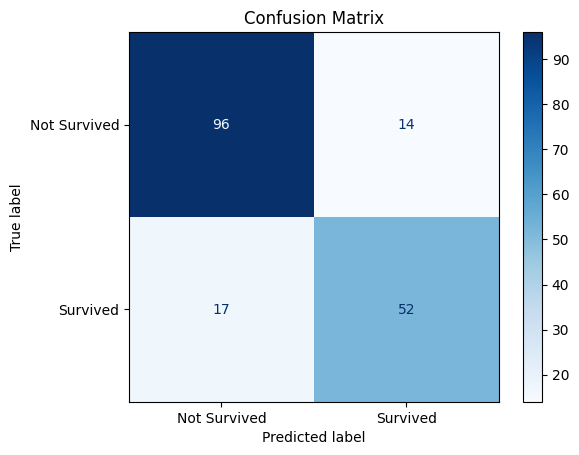

In [9]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Survived', 'Survived'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

### exporting the vanilla model

In [10]:
joblib.dump(lr_pipeline, MODELS_DIR / 'vanilla_lr_pipeline.pkl')
print(f"Model saved to {MODELS_DIR.name}/vanilla_lr_pipeline.pkl")

Model saved to tmp_models/vanilla_lr_pipeline.pkl


# XGBoost:

In [11]:
## imports and prebuilt:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split, cross_val_score,StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve,f1_score,recall_score,precision_score
import joblib   
import matplotlib.pyplot as plt
from scipy.stats import randint,uniform

## section1 : data

In [12]:
def engineer_features(df):
    df = df.copy()
    df["Title"]      = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
    title_map        = {
        "Mr": "Mr", "Miss": "Miss", "Mrs": "Mrs", "Master": "Master",
        "Dr": "Rare", "Rev": "Rare", "Col": "Rare", "Major": "Rare",
        "Mlle": "Miss", "Countess": "Rare", "Ms": "Miss", "Lady": "Rare",
        "Jonkheer": "Rare", "Don": "Rare", "Mme": "Mrs", "Capt": "Rare", "Sir": "Rare"
    }
    df["Title"]      = df["Title"].map(title_map).fillna("Rare")
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"]    = (df["FamilySize"] == 1).astype(int)
    df["HasCabin"]   = df["Cabin"].notna().astype(int)
    df["Fare_log"]   = np.log1p(df["Fare"])
    return df

train_df = pd.read_csv(DATA_DIR / 'train.csv')
train_df = engineer_features(train_df)    

In [13]:
DROP_COLS = ['PassengerId', 'Name', 'Ticket', 'Cabin', 'Fare', 'SibSp', 'Parch']

X = train_df.drop(columns=DROP_COLS + ['Survived'])
y = train_df['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

NUM_COLS = ['Age', 'Fare_log', 'FamilySize', 'IsAlone', 'HasCabin']
CAT_COLS = ['Pclass', 'Sex', 'Embarked', 'Title']

preprocessor =  ColumnTransformer([
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sca', StandardScaler())
    ]), NUM_COLS),
    ('cat', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('one', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), CAT_COLS)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
spw = round((y_train == 0).sum() / (y_train == 1).sum(), 3)  # scale_pos_weight for XGBoost

## section 2: randomized search tuning:

In [14]:
param_dist ={
    'model__n_estimators': randint(150,600),
    'model__learning_rate': [0.01,0.02,0.05,0.1],
    'model__max_depth': [3,4,5],
    'model__subsample': uniform(0.6, 0.25),
    'model__colsample_bytree': uniform(0.5, 0.35),
    'model__min_child_weight': [3,5,7,10],
    'model__gamma': uniform(0.1, 0.4),
    'model__reg_alpha': uniform(0.1, 1.5),
    'model__reg_lambda': uniform(1.0, 3.0),
    'model__scale_pos_weight': [1,spw]
}
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', xgb.XGBClassifier(
        eval_metric='auc',
        random_state=42,
        n__jobs=-1,
        verbosity=0
    ))
])

search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=50,
    cv = cv,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42,
    verbose=1,
    refit=True
)
print("running randomized search --- 50iter x 5 folds = 250 fits")
search.fit(X_train, y_train)

best_model = search.best_estimator_
print("best estimators_______")
for i,j in search.best_params_.items():
    print(f"{i:<35} : {j}")



running randomized search --- 50iter x 5 folds = 250 fits


Fitting 5 folds for each of 50 candidates, totalling 250 fits


best estimators_______
model__colsample_bytree             : 0.6964470191493237
model__gamma                        : 0.40838687198182444
model__learning_rate                : 0.05
model__max_depth                    : 5
model__min_child_weight             : 3
model__n_estimators                 : 356
model__reg_alpha                    : 0.7413115275378245
model__reg_lambda                   : 1.0762573802322857
model__scale_pos_weight             : 1
model__subsample                    : 0.650429800583849


## section 3: validate on held out set

In [15]:
y_val_prob = best_model.predict_proba(X_test)[:,1]
y_val_pred = best_model.predict(X_test)
test_auc = roc_auc_score(y_test, y_val_prob)
gap = test_auc - search.best_score_

print("Validation Results::___________")
print(f" CV Mean : {search.best_score_:.4f}")
print(f" Test AUC : {test_auc:.4f}")
print(f" Gap (Test AUC - CV Mean) : {gap:.4f}-----{'✓' if abs(gap) < 0.03 else '⚠ check overfit'}")
print(f"\n {classification_report(y_test, y_val_pred, target_names=['Not Survived', 'Survived'])}")


Validation Results::___________
 CV Mean : 0.8971
 Test AUC : 0.8495
 Gap (Test AUC - CV Mean) : -0.0476-----⚠ check overfit

               precision    recall  f1-score   support

Not Survived       0.82      0.87      0.85       110
    Survived       0.77      0.70      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



## Section 4: threshold tuning

In [16]:
thresholds = np.arange(0.1, 0.91, 0.01)
f1_scores = [f1_score(y_test,(y_val_prob >= t).astype(int),average='macro',zero_division=0) for t in thresholds]
best_thresh = thresholds[np.argmax(f1_scores)]
best_f1 = max(f1_scores)
default_f1 = f1_score(y_test, y_val_pred, average='macro')

print("after threshold tuning:")
print(f"default 0.5 threshold F1 score : {default_f1:.4f}")
print(f"best threshold : {best_thresh:.2f} with F1 score : {best_f1:.4f}, gain={best_f1 - default_f1:.4f}")
print(f"using the threshold : {best_thresh:.2f} for final predictions.")

after threshold tuning:
default 0.5 threshold F1 score : 0.7893
best threshold : 0.40 with F1 score : 0.8177, gain=0.0284
using the threshold : 0.40 for final predictions.


In [17]:
## kaggle submission::
test_df = pd.read_csv(DATA_DIR / 'test.csv')
test_df = engineer_features(test_df)

X_kaggle = test_df.drop(columns=DROP_COLS)
test_probs = best_model.predict_proba(X_kaggle)[:,1]
test_preds = (test_probs >= best_thresh).astype(int)

##sanity::
print(f"Shape          : {test_preds.shape}  → must be (418,)")
print(f"Predicted dead : {(test_preds == 0).sum()}")
print(f"Predicted surv : {(test_preds == 1).sum()}")
print(f"Survival rate  : {test_preds.mean():.3f}  (train was {y.mean():.3f})")

Shape          : (418,)  → must be (418,)
Predicted dead : 252
Predicted surv : 166
Survival rate  : 0.397  (train was 0.384)


In [18]:
submission = pd.DataFrame({
    "PassengerId": test_df["PassengerId"],
    "Survived":    test_preds
})
print(f"\n{submission.head(10).to_string(index=False)}")
submission.to_csv("submission_titanic.csv", index=False)
print("\nsubmission_titanic.csv ready — upload to Kaggle.")


 PassengerId  Survived
         892         0
         893         0
         894         0
         895         0
         896         1
         897         0
         898         1
         899         0
         900         1
         901         0

submission_titanic.csv ready — upload to Kaggle.


Scored only: 0.76 ranked - 10559;
So time for version 2 from scratch- just the modelling part. 
EDA is not my credit, modelling is !! lets see!

# v2: with voting classifier:

In [19]:
## imports:
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression


In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


## RF:__1

In [21]:
rf_param_dist = {
    'model__n_estimators': randint(200,600),
    'model__max_depth': [3,4,5,6,7,8,9,10,None],
    'model__min_samples_split': [4,6,8,10],
    'model__min_samples_leaf': [2,4,6,8],
    'model__max_features': ['sqrt', 'log2', 0.5],
    'model__class_weight': [None, 'balanced', 'balanced_subsample']
}
rf_pipeline = Pipeline([
    ('preprocessor',preprocessor),
    ('model',RandomForestClassifier(random_state=42, n_jobs=-1,bootstrap=True, oob_score=True))
])

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_dist,
    n_iter=50,
    cv = cv,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42,
    verbose=1,
    refit=True
)
print("running randomized search for RF --- 50iter x 5 folds = 250 fits")
rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_
print("best RF estimators_______")
for i,j in rf_search.best_params_.items():
    print(f"{i:<35} : {j}")

## validation::
rf_val_prob = best_rf.predict_proba(X_test)[:,1]
rf_val_pred = best_rf.predict(X_test)
rf_test_auc = roc_auc_score(y_test, rf_val_prob)
rf_gap = rf_test_auc - rf_search.best_score_
print("RF Validation Results::___________")
print(f" CV Mean : {rf_search.best_score_:.4f}")
print(f" Test AUC : {rf_test_auc:.4f}")
print(f" Gap (Test AUC - CV Mean) : {rf_gap:.4f}-----{'✓' if abs(rf_gap) < 0.03 else '⚠ check overfit'}")
print(f"\n {classification_report(y_test, rf_val_pred, target_names=['Not Survived', 'Survived'])}")

running randomized search for RF --- 50iter x 5 folds = 250 fits
Fitting 5 folds for each of 50 candidates, totalling 250 fits


best RF estimators_______
model__class_weight                 : None
model__max_depth                    : None
model__max_features                 : 0.5
model__min_samples_leaf             : 4
model__min_samples_split            : 4
model__n_estimators                 : 315
RF Validation Results::___________
 CV Mean : 0.8873
 Test AUC : 0.8494
 Gap (Test AUC - CV Mean) : -0.0379-----⚠ check overfit

               precision    recall  f1-score   support

Not Survived       0.80      0.90      0.85       110
    Survived       0.80      0.65      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.78       179
weighted avg       0.80      0.80      0.80       179



In [22]:
## check with xgb once::
xgb_val_auc = roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1])
diff = abs(rf_test_auc - xgb_val_auc)
print(f"  XGBoost Val AUC : {xgb_val_auc:.4f}")
print(f"  RF Val AUC      : {rf_test_auc:.4f}")
print(f"  Difference      : {diff:.4f}  "
      f"{'✓ both strong — good ensemble' if diff < 0.03 else '⚠ gap is large — RF may drag ensemble'}")

  XGBoost Val AUC : 0.8495
  RF Val AUC      : 0.8494
  Difference      : 0.0001  ✓ both strong — good ensemble


In [23]:
## lr for diversity::
lr_pipeline = Pipeline([
    ('preprocessor',preprocessor),
    ('model',LogisticRegression(max_iter=1000,random_state =42,C=0.1,penalty='l2',class_weight='balanced'))
])
lr_pipeline.fit(X_train,y_train)
lr_val_prob = lr_pipeline.predict_proba(X_test)[:,1]
lr_val_pred = lr_pipeline.predict(X_test)
lr_val_auc = roc_auc_score(y_test, lr_val_prob)
print(f"  Logistic Regression Val AUC : {lr_val_auc:.4f}")
print(f"  XGBoost Val AUC           : {xgb_val_auc:.4f}")
print(f"  RF Val AUC                : {rf_test_auc:.4f}")
print(f"  LR vs XGB AUC gap         : {abs(lr_val_auc - xgb_val_auc):.4f}")
print(f"  LR vs RF AUC gap         : {abs(lr_val_auc - rf_test_auc):.4f}")
print(f"  LR may add diversity to ensemble : {'✓' if abs(lr_val_auc - xgb_val_auc) > 0.02 and abs(lr_val_auc - rf_test_auc) > 0.02 else '⚠ may not add much diversity'}")

  Logistic Regression Val AUC : 0.8542
  XGBoost Val AUC           : 0.8495
  RF Val AUC                : 0.8494
  LR vs XGB AUC gap         : 0.0047
  LR vs RF AUC gap         : 0.0047
  LR may add diversity to ensemble : ⚠ may not add much diversity


In [24]:
## voting classifier ensemble::
voting_clf = VotingClassifier(
    estimators=[
        ('xgb', best_model),
        ('rf', best_rf),
        ('lr', lr_pipeline)
    ],
    voting='soft',
    n_jobs=-1,
    weights = [2,2,3]  # giving more weight to LR for better F1
)
print("Fitting Voting Classifier Ensemble...")
voting_clf.fit(X_train, y_train)

vote_val_prob = voting_clf.predict_proba(X_test)[:,1]
vote_val_pred = voting_clf.predict(X_test)
vote_val_auc = roc_auc_score(y_test, vote_val_prob)
print(f"Voting Classifier Val AUC : {vote_val_auc:.4f}")
print(f"  vs XGBoost AUC gap       : {abs(vote_val_auc - xgb_val_auc):.4f}")
print(f"  vs RF AUC gap        : {abs(vote_val_auc - rf_test_auc):.4f}")
print(f"  vs LR AUC gap        : {abs(vote_val_auc - lr_val_auc):.4f}")
print(f"Ensemble may improve performance : {'✓' if vote_val_auc > max(xgb_val_auc, rf_test_auc, lr_val_auc) else '⚠ may not improve over best base model'}")
lift = vote_val_auc - max(xgb_val_auc, rf_test_auc, lr_val_auc)
print(f"Ensemble Lift over best base model : {lift:.4f}")
print(f"\n {classification_report(y_test, vote_val_pred, target_names=['Not Survived', 'Survived'])}")

Fitting Voting Classifier Ensemble...


Voting Classifier Val AUC : 0.8560
  vs XGBoost AUC gap       : 0.0065
  vs RF AUC gap        : 0.0066
  vs LR AUC gap        : 0.0018
Ensemble may improve performance : ✓
Ensemble Lift over best base model : 0.0018

               precision    recall  f1-score   support

Not Survived       0.85      0.87      0.86       110
    Survived       0.79      0.75      0.77        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.82       179
weighted avg       0.83      0.83      0.83       179



In [25]:
## threshold tuning for ensemble::
thresholds = np.arange(0.10, 0.91, 0.01)
f1_scores = [f1_score(y_test,(vote_val_prob >= t).astype(int),average='macro',zero_division=0) for t in thresholds]
best_thresh = thresholds[np.argmax(f1_scores)]
best_f1 = max(f1_scores)
default_f1 = f1_score(y_test, vote_val_pred, average='macro')
print("after threshold tuning:")
print(f"default 0.5 threshold F1 score : {default_f1:.4f}")
print(f"best threshold : {best_thresh:.2f} with F1 score : {best_f1:.4f}, gain={best_f1 - default_f1:.4f}")

after threshold tuning:
default 0.5 threshold F1 score : 0.8157
best threshold : 0.48 with F1 score : 0.8167, gain=0.0010


In [26]:
best_thresh_final = 0.50

test_df = pd.read_csv(DATA_DIR / 'test.csv')
test_df = engineer_features(test_df)

X_kaggle = test_df.drop(columns=DROP_COLS)

test_probs = voting_clf.predict_proba(X_kaggle)[:, 1]
test_preds = (test_probs >= best_thresh_final).astype(int)

print(f"Shape          : {test_preds.shape}")
print(f"Predicted dead : {(test_preds == 0).sum()}")
print(f"Predicted surv : {(test_preds == 1).sum()}")
print(f"Survival rate  : {test_preds.mean():.3f}  (train was {y.mean():.3f})")

submission = pd.DataFrame({
    "PassengerId": test_df["PassengerId"],
    "Survived":    test_preds
})
submission.to_csv("submission_voting.csv", index=False)
print("Done — upload submission_voting.csv to Kaggle.")

Shape          : (418,)
Predicted dead : 253
Predicted surv : 165
Survival rate  : 0.395  (train was 0.384)
Done — upload submission_voting.csv to Kaggle.


# training on full dataset: Jai Mata Di

In [27]:
best_model.fit(X,y)
best_rf.fit(X,y)
lr_pipeline.fit(X,y)
voting_clf.fit(X,y)
test_preds =(voting_clf.predict_proba(X_kaggle)[:, 1] >= 0.50).astype(int)

In [28]:
submission = pd.DataFrame({
    "PassengerId": test_df["PassengerId"],
    "Survived":    test_preds
})
submission.to_csv("submission_voting_fulltest.csv", index=False)
print("Done — upload submission_voting_fulltest.csv to Kaggle.")

Done — upload submission_voting_fulltest.csv to Kaggle.
